# 00_Data_Audit — Home Credit Data Quality Audit

**Projet :** Credit Risk Scorecard · **Phase 1** — ingestion et audit qualité · Données : Home Credit Default Risk (Kaggle, téléchargement manuel).

Prérequis : `scripts/verify_raw_data.py` puis `scripts/load_to_database.py` ont été exécutés (base `database/credit_risk.duckdb`).
Ce notebook ouvre la base **en lecture seule**, exécute `database/00_quality_checks.sql` et produit les figures `output/00_*.png`.
Aucune transformation n'est appliquée ici : les décisions proposées sont validées puis mises en œuvre en Phase 2.
`application_test` (sans `TARGET`) n'intervient jamais dans l'analyse de la cible.

In [1]:
# --- Setup : vérification du répertoire de travail, connexion DuckDB en lecture seule ---
import os
import sys
from pathlib import Path

cwd = Path.cwd()
# Jupyter / VS Code lancent le noyau dans notebooks/ : on remonte d'un niveau si c'est le cas.
if cwd.name == "notebooks" and (cwd.parent / "scripts" / "config.py").is_file():
    os.chdir(cwd.parent)
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name != "credit-risk-scorecard" or not (PROJECT_ROOT / "scripts" / "config.py").is_file():
    raise RuntimeError(
        f"Répertoire de travail inattendu : {PROJECT_ROOT}. "
        "Lancer le notebook depuis la racine credit-risk-scorecard/ (ou depuis notebooks/)."
    )
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))

import duckdb
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from config import DB_PATH, FIGURES_DIR
from run_quality_checks import run_checks

if not DB_PATH.exists():
    raise FileNotFoundError(f"{DB_PATH} introuvable : lancer scripts/load_to_database.py")
con = duckdb.connect(str(DB_PATH), read_only=True)
R = run_checks(con)  # {nom de requête: DataFrame}, cf. database/00_quality_checks.sql

# Style des figures : fond clair, axes discrets, une seule teinte (série unique)
BLUE, INK, INK2, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
})
print("Racine :", PROJECT_ROOT.name)
print(f"Python {sys.version.split()[0]} · duckdb {duckdb.__version__} · pandas {pd.__version__} · matplotlib {matplotlib.__version__}")
print(f"Requêtes exécutées : {len(R)}")

Racine : credit-risk-scorecard
Python 3.13.15 · duckdb 1.5.5 · pandas 3.0.6 · matplotlib 3.11.2
Requêtes exécutées : 15


## 1. Volumétrie et intégrité des fichiers

Nombre de lignes et de colonnes par table. `csv_data_lines` = lignes physiques du CSV hors en-tête, comptées par `load_to_database.py` ;
`lines_match = True` signifie que DuckDB a chargé exactement toutes les lignes (aucun fichier tronqué, aucune ligne rejetée ; chargement en mode strict).

In [2]:
vol = R["a_volumetrie"]
display(vol)
print(f"Total : {vol['n_rows'].sum():,} lignes chargées, {vol['size_mb'].sum():,.1f} Mo de CSV")
print("Intégrité des fichiers :", "OK — toutes les tables" if vol["lines_match"].all() else "ÉCART détecté")

,table_name,n_rows,n_cols,size_mb,csv_data_lines,lines_match,encoding
0,bureau_balance,27299925,3,358.2,27299925,True,utf-8
1,installments_payments,13605401,8,689.6,13605401,True,utf-8
2,pos_cash_balance,10001358,8,374.5,10001358,True,utf-8
3,credit_card_balance,3840312,23,404.9,3840312,True,utf-8
4,bureau,1716428,17,162.1,1716428,True,utf-8
5,previous_application,1670214,37,386.2,1670214,True,utf-8
6,application_train,307511,122,158.4,307511,True,utf-8
7,application_test,48744,121,25.3,48744,True,utf-8
8,homecredit_columns_description,219,4,0.0,219,True,cp1252


Total : 58,490,112 lignes chargées, 2,559.2 Mo de CSV
Intégrité des fichiers : OK — toutes les tables


## 2. Clés et intégrité référentielle

In [3]:
display(Markdown("**Unicité de `SK_ID_CURR`** (et recouvrement train / test)"))
display(R["b_unicite_sk_id_curr"])
display(Markdown("**Unicité des clés des tables secondaires**"))
display(R["c_unicite_cles_secondaires"])
display(Markdown("**Intégrité référentielle** — part des clés distinctes de la table enfant retrouvées dans la table parent"))
display(R["d_integrite_referentielle"])
display(Markdown("**Couverture** — part des demandes d'`application_train` ayant un historique dans chaque table"))
display(R["d_couverture_application_train"])

**Unicité de `SK_ID_CURR`** (et recouvrement train / test)

,table_name,n_lignes,n_distincts,n_doublons,n_nulls
0,application_train,307511,307511,0,0
1,application_test,48744,48744,0,0
2,train ∩ test,0,0,<NA>,<NA>


**Unicité des clés des tables secondaires**

,cle,n_lignes,n_distincts,n_doublons,n_nulls
0,bureau.SK_ID_BUREAU,1716428,1716428,0,0
1,previous_application.SK_ID_PREV,1670214,1670214,0,0


**Intégrité référentielle** — part des clés distinctes de la table enfant retrouvées dans la table parent

,relation,n_cles_distinctes,n_retrouvees,pct_retrouvees
0,bureau.SK_ID_CURR → application (train ∪ test),305811,305811,100.00
1,previous_application.SK_ID_CURR → application ...,338857,338857,100.00
2,bureau_balance.SK_ID_BUREAU → bureau,817395,774354,94.73
3,pos_cash_balance.SK_ID_PREV → previous_applica...,936325,898903,96.00
4,installments_payments.SK_ID_PREV → previous_ap...,997752,958905,96.11
5,credit_card_balance.SK_ID_PREV → previous_appl...,104307,92935,89.10


**Couverture** — part des demandes d'`application_train` ayant un historique dans chaque table

,source,n_clients,pct_application_train
0,installments_payments,291643,94.84
1,previous_application,291057,94.65
2,pos_cash_balance,289444,94.12
3,bureau,263491,85.69
4,credit_card_balance,86905,28.26


Lecture : les clés orphelines de `bureau_balance`, `pos_cash_balance`, `installments_payments` et `credit_card_balance`
n'ont pas de parent dans l'extrait fourni. Elles seront perdues à la jointure par `SK_ID_BUREAU` / `SK_ID_PREV`, mais ces trois dernières tables
portent aussi `SK_ID_CURR` et peuvent être agrégées directement au niveau client (cf. section 6 et `docs/data_dictionary.md`, schéma relationnel en Mermaid).

## 3. Cible (`application_train` uniquement)

,TARGET,n,pct
0,0,282686,91.93
1,1,24825,8.07


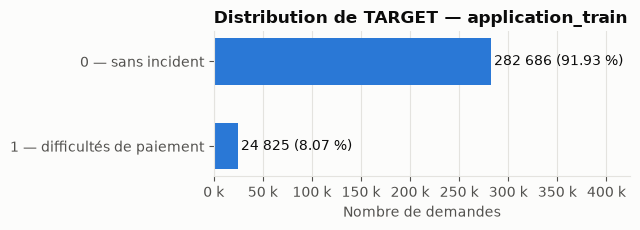

In [4]:
tgt = R["e_distribution_target"]
display(tgt)

fig, ax = plt.subplots(figsize=(6.5, 2.4))
labels = ["0 — sans incident", "1 — difficultés de paiement"]
bars = ax.barh(labels, tgt["n"], color=BLUE, height=0.55)
for b, n, p in zip(bars, tgt["n"], tgt["pct"]):
    ax.text(b.get_width() + tgt["n"].max() * 0.01, b.get_y() + b.get_height() / 2,
            f"{n:,} ({p:.2f} %)".replace(",", " "), va="center", color=INK, fontsize=10)
ax.invert_yaxis()
ax.set_xlim(0, tgt["n"].max() * 1.5)
ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v/1000:.0f} k"))
ax.grid(axis="x", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
ax.set_title("Distribution de TARGET — application_train", loc="left")
ax.set_xlabel("Nombre de demandes")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "00_target_distribution.png", dpi=150)
plt.show()

## 4. Valeurs manquantes (`application_train`)

,tranche,n_colonnes
0,0 %,55
1,]0 ; 10 %[,10
2,[10 ; 50 %[,16
3,≥ 50 %,41


,colonne,n_manquants,pct_manquants
0,COMMONAREA_AVG,214865,69.87
1,COMMONAREA_MEDI,214865,69.87
2,COMMONAREA_MODE,214865,69.87
3,NONLIVINGAPARTMENTS_AVG,213514,69.43
4,NONLIVINGAPARTMENTS_MEDI,213514,69.43
5,NONLIVINGAPARTMENTS_MODE,213514,69.43
6,FONDKAPREMONT_MODE,210295,68.39
7,LIVINGAPARTMENTS_AVG,210199,68.35
8,LIVINGAPARTMENTS_MEDI,210199,68.35
9,LIVINGAPARTMENTS_MODE,210199,68.35


**Scores externes `EXT_SOURCE_*`**

,colonne,n_manquants,pct_manquants
0,EXT_SOURCE_1,173378,56.38
1,EXT_SOURCE_2,660,0.21
2,EXT_SOURCE_3,60965,19.83


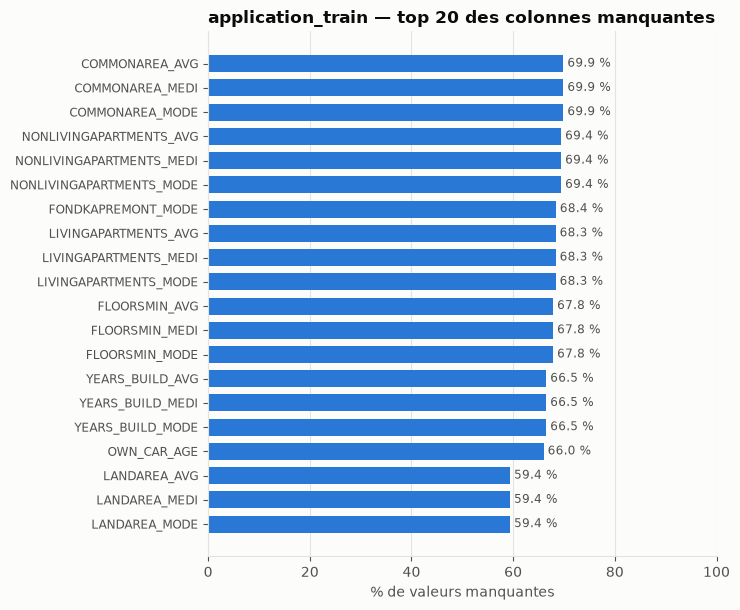

In [5]:
miss = R["f_top20_manquants"]
display(R["f_synthese_manquants"])
display(miss)
display(Markdown("**Scores externes `EXT_SOURCE_*`**"))
display(R["h_ext_source_manquants"])

fig, ax = plt.subplots(figsize=(7.5, 6.2))
ax.barh(miss["colonne"], miss["pct_manquants"], color=BLUE, height=0.7)
for y, p in enumerate(miss["pct_manquants"]):
    ax.text(p + 0.8, y, f"{p:.1f} %", va="center", fontsize=8.5, color=INK2)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.grid(axis="x", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
ax.set_title("application_train — top 20 des colonnes manquantes", loc="left")
ax.set_xlabel("% de valeurs manquantes")
ax.tick_params(axis="y", labelsize=8.5)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "00_top20_missing.png", dpi=150)
plt.show()

Les 20 colonnes les plus lacunaires décrivent presque toutes le logement (`*_AVG`, `*_MODE`, `*_MEDI` : trois statistiques d'une même mesure,
d'où des taux identiques par triplet), plus `OWN_CAR_AGE` (renseigné seulement pour les propriétaires d'un véhicule).

## 5. Anomalies connues

In [6]:
display(Markdown("**`DAYS_EMPLOYED = 365243`** (valeur sentinelle ≈ 1 000 ans d'ancienneté) — effectif et taux de défaut"))
display(R["g1_days_employed_sentinelle"])
display(Markdown("Répartition du groupe sentinelle par `NAME_INCOME_TYPE`"))
display(R["g1_days_employed_sentinelle_income_type"])
display(Markdown("Même sentinelle dans `application_test` (effectif uniquement)"))
display(R["g1_days_employed_sentinelle_test"])
display(Markdown("**`CODE_GENDER`**"))
display(R["g2_code_gender"])
display(Markdown("**Colonnes `DAYS_*` positives** (attendues ≤ 0, comptées en jours avant la demande)"))
display(R["g3_days_positifs"])
display(Markdown("**Sentinelle 365243 dans `previous_application`** (à traiter en Phase 2)"))
display(R["g4_sentinelle_previous_application"])

**`DAYS_EMPLOYED = 365243`** (valeur sentinelle ≈ 1 000 ans d'ancienneté) — effectif et taux de défaut

,groupe,n,pct_lignes,n_defauts,taux_defaut_pct
0,autres,252137,81.99,21835,8.66
1,DAYS_EMPLOYED = 365243,55374,18.01,2990,5.40


Répartition du groupe sentinelle par `NAME_INCOME_TYPE`

,NAME_INCOME_TYPE,n_sentinelle
0,Pensioner,55352
1,Unemployed,22


Même sentinelle dans `application_test` (effectif uniquement)

...

,table_name,CODE_GENDER,n
0,application_train,F,202448
1,application_train,M,105059
2,application_train,XNA,4
3,application_test,F,32678
4,application_test,M,16066


**Colonnes `DAYS_*` positives** (attendues ≤ 0, comptées en jours avant la demande)

,colonne,n_positifs_train,n_positifs_test,n_positifs_train_hors_365243
0,DAYS_BIRTH,0,0,0
1,DAYS_EMPLOYED,55374,9274,0
2,DAYS_ID_PUBLISH,0,0,0
3,DAYS_LAST_PHONE_CHANGE,0,0,0
4,DAYS_REGISTRATION,0,0,0


**Sentinelle 365243 dans `previous_application`** (à traiter en Phase 2)

,colonne,n_365243,pct_lignes
0,DAYS_DECISION,0,0.00
1,DAYS_FIRST_DRAWING,934444,55.95
2,DAYS_FIRST_DUE,40645,2.43
3,DAYS_LAST_DUE,211221,12.65
4,DAYS_LAST_DUE_1ST_VERSION,93864,5.62
5,DAYS_TERMINATION,225913,13.53


## 6. Schéma relationnel

| Table | Grain (1 ligne =) | Clé propre | Clé de jointure |
|---|---|---|---|
| `application_train` / `application_test` | 1 demande de crédit en cours | `SK_ID_CURR` | — |
| `bureau` | 1 crédit externe déclaré au bureau de crédit | `SK_ID_BUREAU` | `SK_ID_CURR` |
| `bureau_balance` | 1 mois d'un crédit externe | — | `SK_ID_BUREAU` |
| `previous_application` | 1 demande antérieure chez Home Credit | `SK_ID_PREV` | `SK_ID_CURR` |
| `pos_cash_balance` | 1 mois d'un prêt POS / cash antérieur | — | `SK_ID_PREV`, `SK_ID_CURR` |
| `installments_payments` | 1 échéance (ou paiement) d'un prêt antérieur | — | `SK_ID_PREV`, `SK_ID_CURR` |
| `credit_card_balance` | 1 mois d'une carte antérieure | — | `SK_ID_PREV`, `SK_ID_CURR` |

```
application ──┬── bureau ── bureau_balance
              └── previous_application ──┬── pos_cash_balance
                                         ├── credit_card_balance
                                         └── installments_payments
```

Toutes les tables enfants ont plusieurs lignes par client : elles doivent être **agrégées au grain `SK_ID_CURR` avant toute jointure** (Phase 2).

Schéma relationnel : voir `docs/data_dictionary.md` (diagramme Mermaid établi d'après la documentation de la compétition Kaggle).

## 7. Synthèse et implications pour la Phase 2
Chiffres calculés ci-dessous à partir des requêtes exécutées.

In [7]:
g = lambda s: f"{s:,}".replace(",", " ")
t = R["e_distribution_target"].set_index("TARGET")
s = R["g1_days_employed_sentinelle"].set_index("groupe")
u = R["b_unicite_sk_id_curr"].set_index("table_name")
ri = R["d_integrite_referentielle"].set_index("relation")
ext = R["h_ext_source_manquants"].set_index("colonne")["pct_manquants"]
xna = R["g2_code_gender"].query("table_name == 'application_train' and CODE_GENDER == 'XNA'")["n"].sum()
n_train = int(t["n"].sum())
sent, autres = s.loc["DAYS_EMPLOYED = 365243"], s.loc["autres"]
bb = ri.loc["bureau_balance.SK_ID_BUREAU → bureau", "pct_retrouvees"]
tranches = R["f_synthese_manquants"].set_index("tranche")["n_colonnes"]

display(Markdown(f"""
**Constats**
- Intégrité des fichiers : {"les 9 CSV sont chargés intégralement (lignes CSV = lignes chargées)" if vol["lines_match"].all() else "écart détecté"} ; {g(int(vol["n_rows"].sum()))} lignes au total.
- `application_train` : {g(n_train)} demandes, taux de défaut **{t.loc[1, "pct"]:.2f} %** ({g(int(t.loc[1, "n"]))} défauts).
- `SK_ID_CURR` unique : {int(u.loc["application_train", "n_doublons"])} doublon dans train, {int(u.loc["application_test", "n_doublons"])} dans test ; aucun identifiant commun aux deux tables.
- `DAYS_EMPLOYED = 365243` : {g(int(sent["n"]))} demandes ({sent["pct_lignes"]:.2f} %), défaut {sent["taux_defaut_pct"]:.2f} % contre {autres["taux_defaut_pct"]:.2f} % pour le reste — groupe quasi exclusivement composé de retraités.
- `CODE_GENDER = 'XNA'` : {int(xna)} lignes.
- {int(tranches.get("≥ 50 %", 0))} colonnes d'`application_train` sur 122 ont au moins 50 % de manquants ; `EXT_SOURCE_1` {ext["EXT_SOURCE_1"]:.2f} %, `EXT_SOURCE_3` {ext["EXT_SOURCE_3"]:.2f} %, `EXT_SOURCE_2` {ext["EXT_SOURCE_2"]:.2f} %.
- `bureau_balance` : {bb:.2f} % des `SK_ID_BUREAU` retrouvés dans `bureau`.

**Implications pour la Phase 2 (décisions proposées, à valider)**
1. `DAYS_EMPLOYED = 365243` → NULL + indicateur `FLAG_DAYS_EMPLOYED_ANOM` (le groupe a un risque propre, il ne faut pas le fondre dans la moyenne).
2. Même sentinelle dans les `DAYS_*` de `previous_application` → NULL avant toute agrégation.
3. `DAYS_*` → années positives ; aucune autre valeur positive anormale n'est présente.
4. Agrégation au grain `SK_ID_CURR` avant jointure gauche sur `application_train`, avec contrôle du nombre de lignes ({g(n_train)} attendues).
5. Les clients sans historique (bureau, demandes antérieures, carte) ont des agrégats NULL : conserver cette absence comme information (catégorie propre au binning).
6. Colonnes de logement très lacunaires : pas de suppression a priori ; le binning optimal traitera le manquant comme une classe, et la sélection par IV tranchera.
7. `CODE_GENDER` (dont 'XNA') : exclu du modèle, conservé pour l'audit d'équité.
"""))


**Constats**
- Intégrité des fichiers : les 9 CSV sont chargés intégralement (lignes CSV = lignes chargées) ; 58 490 112 lignes au total.
- `application_train` : 307 511 demandes, taux de défaut **8.07 %** (24 825 défauts).
- `SK_ID_CURR` unique : 0 doublon dans train, 0 dans test ; aucun identifiant commun aux deux tables.
- `DAYS_EMPLOYED = 365243` : 55 374 demandes (18.01 %), défaut 5.40 % contre 8.66 % pour le reste — groupe quasi exclusivement composé de retraités.
- `CODE_GENDER = 'XNA'` : 4 lignes.
- 41 colonnes d'`application_train` sur 122 ont au moins 50 % de manquants ; `EXT_SOURCE_1` 56.38 %, `EXT_SOURCE_3` 19.83 %, `EXT_SOURCE_2` 0.21 %.
- `bureau_balance` : 94.73 % des `SK_ID_BUREAU` retrouvés dans `bureau`.

**Implications pour la Phase 2 (décisions proposées, à valider)**
1. `DAYS_EMPLOYED = 365243` → NULL + indicateur `FLAG_DAYS_EMPLOYED_ANOM` (le groupe a un risque propre, il ne faut pas le fondre dans la moyenne).
2. Même sentinelle dans les `DAYS_*` de `previous_application` → NULL avant toute agrégation.
3. `DAYS_*` → années positives ; aucune autre valeur positive anormale n'est présente.
4. Agrégation au grain `SK_ID_CURR` avant jointure gauche sur `application_train`, avec contrôle du nombre de lignes (307 511 attendues).
5. Les clients sans historique (bureau, demandes antérieures, carte) ont des agrégats NULL : conserver cette absence comme information (catégorie propre au binning).
6. Colonnes de logement très lacunaires : pas de suppression a priori ; le binning optimal traitera le manquant comme une classe, et la sélection par IV tranchera.
7. `CODE_GENDER` (dont 'XNA') : exclu du modèle, conservé pour l'audit d'équité.


In [8]:
con.close()